# Skład B (TiNbZrHfTaMoWYVSc): optymalizacje GL z celem `Tc_corr` (corr2), mincomp 2–10

- **Runy:** `opt.ratios.gl/sra.TiNbZrHfTaMoWYVSc.kp10.ew0.6.gl.corr2.mu0.1.acqbeta2.stonerbeta0.mixdebye.mincomp<m>.r0.05.max0.7.face0.1`
  (Topola, 2026-11-02/03).
- **Baza startowa:** `databases/sra.TiNbZrHfTaMoWYVSc.kp10.ew0.6.gl.csv`, 1800 losowych składów (1712 w granicach
  optymalizatora).
- **Ustawienia:** wariant GL (G + Lloyd), θ_D z reguły mieszaniny, kara Stonera wyłączona, β = 2, `max_composition = 0.7`.
- **Cel `Tc_corr` (corr2, `consts.py` od commita 7aa080e):** McMillan z μ\* = 0.1 i dwiema poprawkami:
  - θ_D fazy bcc dla Sc (215 K) w regule mieszaniny, λ przeskalowane o (θ_mix/θ_corr)²;
  - sprzężenie elektron–paramagnon tylko na V, α_V = 0.4.

  Dla składów bez V i Sc `Tc_corr2 == Tc_mu0.1`.
- **Liczenie składników:** skład liczy się dla runu tylko wtedy, gdy ma co najmniej mincomp pierwiastków o udziale > 0.05.

Układ notebooka jest taki sam jak w `OptGL_mu0.1_Runs.ipynb` (skład A, sekcje 1–9). Dla każdego punktu liczone są ponownie
`Tc_corr2`, λ_corr, λ_es i θ_corr (przez `process_kkr.compute_tc_corrected`, z assertem zgodności z wartością zapisaną
w runie). Porównanie corr2 z wariantami plain/corr (tylko mc 2/3/7) jest w `OptGL_B_corr_Runs.ipynb`.
Notebook nie zapisuje plików graficznych.

In [1]:
from pathlib import Path
import json, re, sys, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('../opt.ratios.gl')
TARGET = 'Tc_corr2'
RATIO = 0.05
ELEMENTS = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'V', 'Sc']
EL_COLORS = dict(zip(ELEMENTS, plt.cm.tab10.colors))
MCS = list(range(2, 11))
pd.set_option('display.width', 250, 'display.max_columns', 40, 'display.max_rows', 200)

sys.path.insert(0, '../scripts')
import src.process_kkr as pk
assert (dict(pk.TC_CORR_THETA_BCC_K), dict(pk.TC_CORR_SF_ALPHA)) == ({'Sc': 215.0}, {'V': 0.4}), \
    'consts.py zmienione od runów corr2'


def run_dir(mc, tag='corr2.mu0.1'):
    return BASE / f'sra.TiNbZrHfTaMoWYVSc.kp10.ew0.6.gl.{tag}.acqbeta2.stonerbeta0.mixdebye.mincomp{mc}.r0.05.max0.7.face0.1'

Using AKAIMODBIN: /home/rafal/WORK/HEA/RKKY/cpa2002v010.potential2026/specx


In [2]:
def parse_name(name):
    return {el: float(x) for el, x in re.findall(r'([A-Z][a-z]?)(\d+\.\d+)', name)}


def n_comp(row):
    return int(sum(row.get(el, 0.0) > RATIO for el in ELEMENTS))


def comp_str(row, thr=0.005):
    parts = [(el, row[el]) for el in ELEMENTS if row.get(el, 0.0) > thr]
    return ' '.join(f'{el}{100*v:.0f}' for el, v in sorted(parts, key=lambda p: -p[1]))


def iter_results(it_dir):
    # (results, selection_info) z computation.tar albo z rozpakowanego computation/
    tf = it_dir / 'computation.tar'
    if tf.exists():
        with tarfile.open(tf) as t:
            sel, res = {}, {}
            for m in t.getmembers():
                key = m.name.rstrip('/').split('/')[-2] if '/' in m.name.rstrip('/') else None
                if m.name.endswith('results.json'):
                    res[key] = json.load(t.extractfile(m))
                elif m.name.endswith('selection_info.json'):
                    sel[key] = json.load(t.extractfile(m))
            for k, r in res.items():
                yield r, sel.get(k, {})
        return
    for c in (it_dir / 'computation').glob('*'):
        rf, sf = c / 'results.json', c / 'selection_info.json'
        if rf.exists():
            yield json.loads(rf.read_text()), (json.loads(sf.read_text()) if sf.exists() else {})


# punkty startowe (te same we wszystkich runach): Tc_corr2 z runu corr2, Tc_mu0.1 z runu plain mc2
_init = pd.concat([
    pd.read_csv(run_dir(2) / 'init_tc_comparison.csv').set_index('name')['Tc_corr_computed'].rename('Tc_corr2'),
    pd.read_csv(run_dir(2, 'mu0.1') / 'init_tc_comparison.csv').set_index('name')['Tc_mu0.1_computed'].rename('Tc_mu0.1')],
    axis=1)
assert _init.notna().all().all()
_init = _init.reset_index()
INIT = pd.concat([pd.DataFrame([parse_name(n) for n in _init['name']]).reindex(columns=ELEMENTS).fillna(0.0),
                  _init[['Tc_mu0.1', 'Tc_corr2']]], axis=1)
INIT['Tc'] = INIT[TARGET]
INIT['iteration'] = 0
INIT['source'] = 'init'


def load_run(mc):
    d = run_dir(mc)
    params = json.loads((d / 'parameters.json').read_text())
    assert params['min_components'] == mc
    rows = []
    for it_dir in d.glob('iteration_*'):
        it = int(it_dir.name.split('_')[1])
        for r, s in iter_results(it_dir):
            c = pk.compute_tc_corrected(r, {el: r.get(el, 0.0) for el in ELEMENTS})
            assert abs(c['Tc_corr'] - r['Tc_corr']) < 1e-8, (mc, it)
            row = {el: r.get(el, 0.0) for el in ELEMENTS}
            row.update(iteration=it, source=s.get('source', '?'), Tc=c['Tc_corr'], Tc_corr2=c['Tc_corr'],
                       **{'Tc_mu0.1': r.get('Tc_mu0.1')},
                       lam=r.get('lambda'), lam_corr=c['lambda_corr'], lam_es=c['lambda_es'],
                       theta=r.get('thetaDB_K'), theta_corr=c['theta_corr'], eta=r.get('eta_mix'), VEC=r.get('VEC'),
                       pred=s.get('pred_target'), pred_std=s.get('pred_target_std'), dist=s.get('composition_distance'))
            rows.append(row)
    opt = pd.DataFrame(rows).sort_values('iteration').reset_index(drop=True)
    df = pd.concat([INIT, opt], ignore_index=True)
    df['n_comp'] = df.apply(n_comp, axis=1)
    df['valid'] = df['n_comp'] >= mc
    df['comp'] = df.apply(comp_str, axis=1)
    df['mincomp'] = mc
    df['run'] = f'mc{mc}'
    log = (d / 'optimization_log.txt').read_text()
    m = re.search(r'EARLY STOP after iteration (\d+)', log)
    status = f'early stop @ {m.group(1)}' if m else 'bez early stop'
    gaps = sorted(set(range(1, int(opt.iteration.max()) + 1)) - set(opt.iteration.unique()))
    if gaps:
        status += f', brak iteracji {gaps}'
    return dict(mc=mc, label=f'mc{mc}', params=params, df=df, status=status,
                n_iter=int(opt.iteration.max()), n_done=int(opt.iteration.nunique()))


runs = [load_run(mc) for mc in MCS]
ALL = pd.concat([r['df'] for r in runs], ignore_index=True)
for r in runs:
    d = r['df']
    print(f"{r['label']:>5}: init={int((d.iteration == 0).sum())} (valid {int(((d.iteration == 0) & d.valid).sum())}), "
          f"opt={int((d.iteration > 0).sum())}, iteracje={r['n_done']} (ostatnia {r['n_iter']}), {r['status']}")

  mc2: init=1712 (valid 1712), opt=160, iteracje=16 (ostatnia 16), early stop @ 16
  mc3: init=1712 (valid 1671), opt=230, iteracje=23 (ostatnia 23), early stop @ 23
  mc4: init=1712 (valid 1579), opt=240, iteracje=24 (ostatnia 24), early stop @ 24
  mc5: init=1712 (valid 1420), opt=240, iteracje=24 (ostatnia 24), early stop @ 24
  mc6: init=1712 (valid 1154), opt=240, iteracje=24 (ostatnia 24), early stop @ 24
  mc7: init=1712 (valid 743), opt=370, iteracje=37 (ostatnia 37), early stop @ 37
  mc8: init=1712 (valid 360), opt=210, iteracje=21 (ostatnia 21), early stop @ 21
  mc9: init=1712 (valid 125), opt=280, iteracje=28 (ostatnia 28), early stop @ 28
 mc10: init=1712 (valid 0), opt=240, iteracje=24 (ostatnia 24), early stop @ 24


## 1. Tabela zbiorcza: najlepszy poprawny skład każdego runu

In [3]:
def summary(rs):
    out = []
    for r in rs:
        d = r['df']; v = d[d.valid]
        i0, io = v[v.iteration == 0], v[v.iteration > 0]
        best = v.loc[v.Tc.idxmax()]
        out.append({'mincomp': r['mc'], 'iters': r['n_done'], 'status': r['status'],
                    'n_init_valid': len(i0), 'init_best': i0.Tc.max(), 'opt_best': io.Tc.max(),
                    'gain_K': io.Tc.max() - i0.Tc.max(), 'best_iter': int(best.iteration),
                    'frac_new_valid': d[d.iteration > 0].valid.mean(),
                    'champion': best.comp, 'n_el': int(best.n_comp), 'Tc_mu0.1': best['Tc_mu0.1'],
                    'lam': best.lam, 'lam_corr': best.lam_corr, 'lam_es': best.lam_es,
                    'theta': best.theta, 'theta_corr': best.theta_corr, 'VEC': best.VEC})
    return pd.DataFrame(out).set_index('mincomp')

FMT = {'init_best': '{:.2f}', 'opt_best': '{:.2f}', 'gain_K': '{:+.2f}', 'frac_new_valid': '{:.0%}', 'Tc_mu0.1': '{:.2f}',
       'lam': '{:.2f}', 'lam_corr': '{:.2f}', 'lam_es': '{:.3f}', 'theta': '{:.0f}', 'theta_corr': '{:.0f}', 'VEC': '{:.2f}'}
summ = summary(runs)
summ.style.format(FMT, na_rep='—')

,iters,status,n_init_valid,init_best,opt_best,gain_K,best_iter,frac_new_valid,champion,n_el,Tc_mu0.1,lam,lam_corr,lam_es,theta,theta_corr,VEC
mincomp,,,,,,,,,,,,,,,,,
2,16,early stop @ 16,1712,18.70,18.97,+0.27,1,100%,Nb61 Zr39,2,18.97,1.14,1.14,0.000,273,273,4.61
3,23,early stop @ 23,1671,13.61,17.88,+4.27,8,100%,Nb54 Zr40 Ta5,3,17.88,1.10,1.10,0.000,271,271,4.60
4,24,early stop @ 24,1579,12.44,16.69,+4.25,9,100%,Nb58 Zr31 Sc6 Ta5,4,15.76,0.99,1.05,0.000,276,268,4.58
5,24,early stop @ 24,1420,9.57,15.53,+5.97,9,100%,Nb62 Zr22 Sc5 Ti5 Ta5,5,14.63,0.93,0.98,0.000,284,276,4.62
6,24,early stop @ 24,1154,8.51,14.31,+5.80,9,100%,Nb58 Zr22 Ti5 Sc5 Ta5 Hf5,6,13.42,0.89,0.94,0.000,283,275,4.57
7,37,early stop @ 37,743,7.89,12.87,+4.98,22,100%,Nb67 Zr7 Ti6 Ta5 Y5 Hf5 Sc5,7,12.02,0.84,0.88,0.000,284,277,4.62
8,21,early stop @ 21,360,7.51,11.20,+3.69,6,100%,Nb55 Zr12 Ti6 Sc6 Ta5 Y5 Hf5 Mo5,8,10.28,0.76,0.80,0.000,294,286,4.60
9,28,early stop @ 28,125,5.75,9.37,+3.62,13,100%,Nb55 Zr7 Sc6 V6 Ti6 Mo5 Y5 Hf5 Ta5,9,9.33,0.72,0.76,0.013,300,292,4.66
10,24,early stop @ 24,0,—,7.24,—,9,100%,Nb47 Zr8 Y8 Sc6 Ta6 Hf5 Mo5 W5 Ti5 V5,10,7.12,0.65,0.68,0.011,304,296,4.65


## 2. Zbieżność: najlepszy dotąd (tylko poprawne) i wszystkie nowe punkty w iteracji

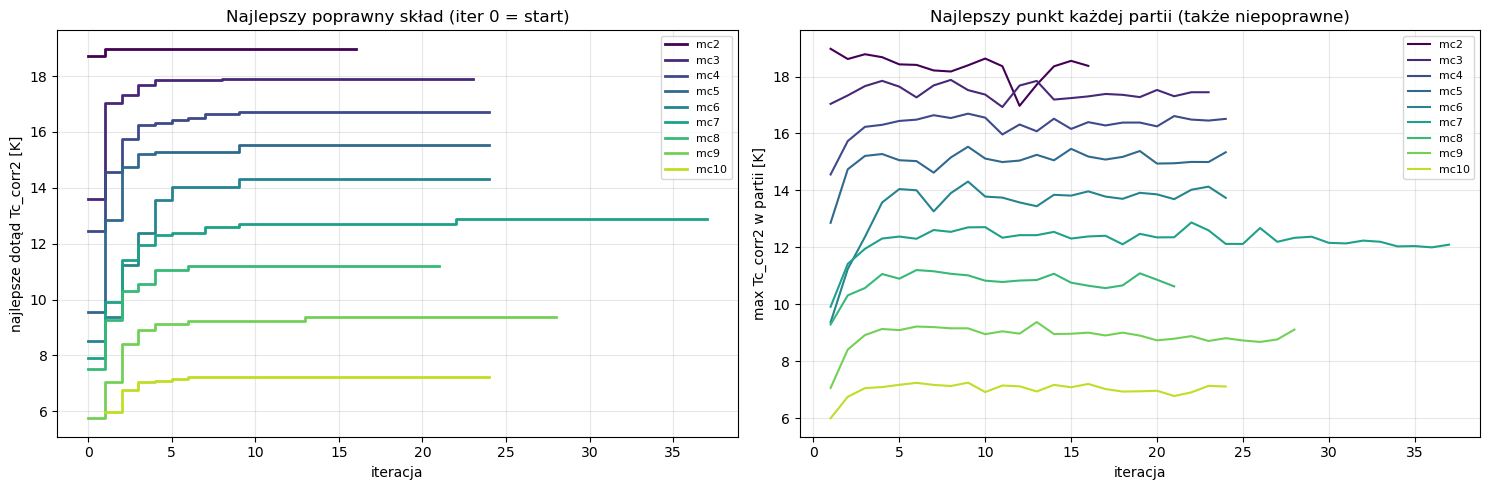

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(runs)))
for r, c in zip(runs, cmap):
    d = r['df']; v = d[d.valid]
    its = np.arange(0, r['n_iter'] + 1)
    ax[0].step(its, [v[v.iteration <= i].Tc.max() for i in its], where='post', color=c, lw=2, label=r['label'])
    io = d[d.iteration > 0]
    ax[1].plot(io.groupby('iteration').Tc.max(), color=c, lw=1.5, label=r['label'])
ax[0].set(xlabel='iteracja', ylabel=f'najlepsze dotąd {TARGET} [K]', title='Najlepszy poprawny skład (iter 0 = start)')
ax[1].set(xlabel='iteracja', ylabel=f'max {TARGET} w partii [K]', title='Najlepszy punkt każdej partii (także niepoprawne)')
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

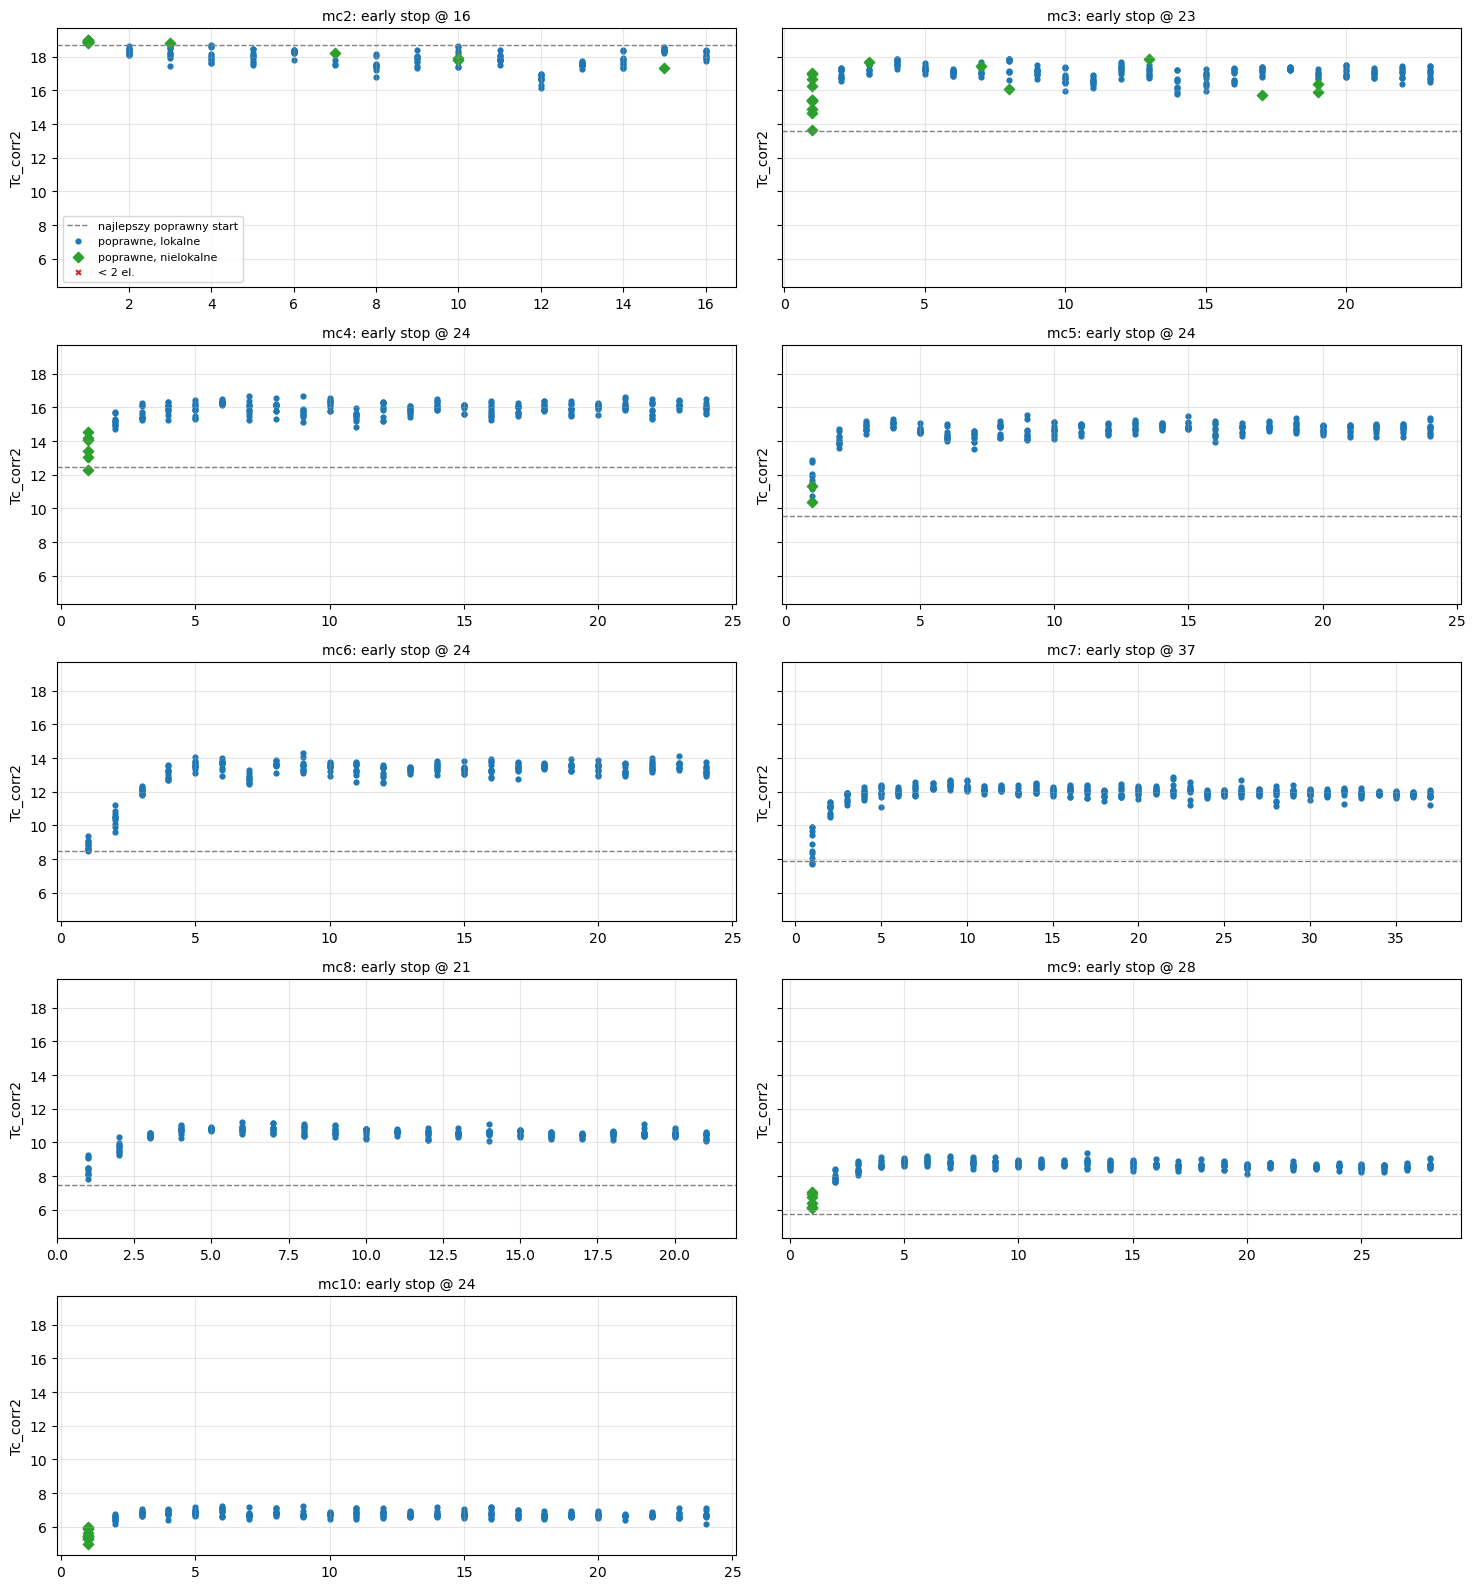

In [5]:
def scatter_runs(rs):
    n = len(rs)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(15, 3.2 * ((n + 1) // 2)), sharey=True, squeeze=False)
    for a, r in zip(axes.flat, rs):
        d = r['df']; io = d[d.iteration > 0]
        a.axhline(d[(d.iteration == 0) & d.valid].Tc.max(), color='gray', ls='--', lw=1, label='najlepszy poprawny start')
        loc = io.source == 'local'
        a.scatter(io[io.valid & loc].iteration, io[io.valid & loc].Tc, s=12, c='C0', label='poprawne, lokalne')
        a.scatter(io[io.valid & ~loc].iteration, io[io.valid & ~loc].Tc, s=28, c='C2', marker='D', label='poprawne, nielokalne')
        a.scatter(io[~io.valid].iteration, io[~io.valid].Tc, s=12, c='C3', marker='x', label=f"< {r['mc']} el.")
        a.set_title(f"{r['label']}: {r['status']}", fontsize=10); a.grid(alpha=.3); a.set_ylabel(TARGET)
    axes.flat[0].legend(fontsize=8)
    for a in list(axes.flat)[n:]:
        a.axis('off')
    plt.tight_layout(); plt.show()

scatter_runs(runs)

## 3. Skład ocenianych partii: średni udział pierwiastka w iteracji

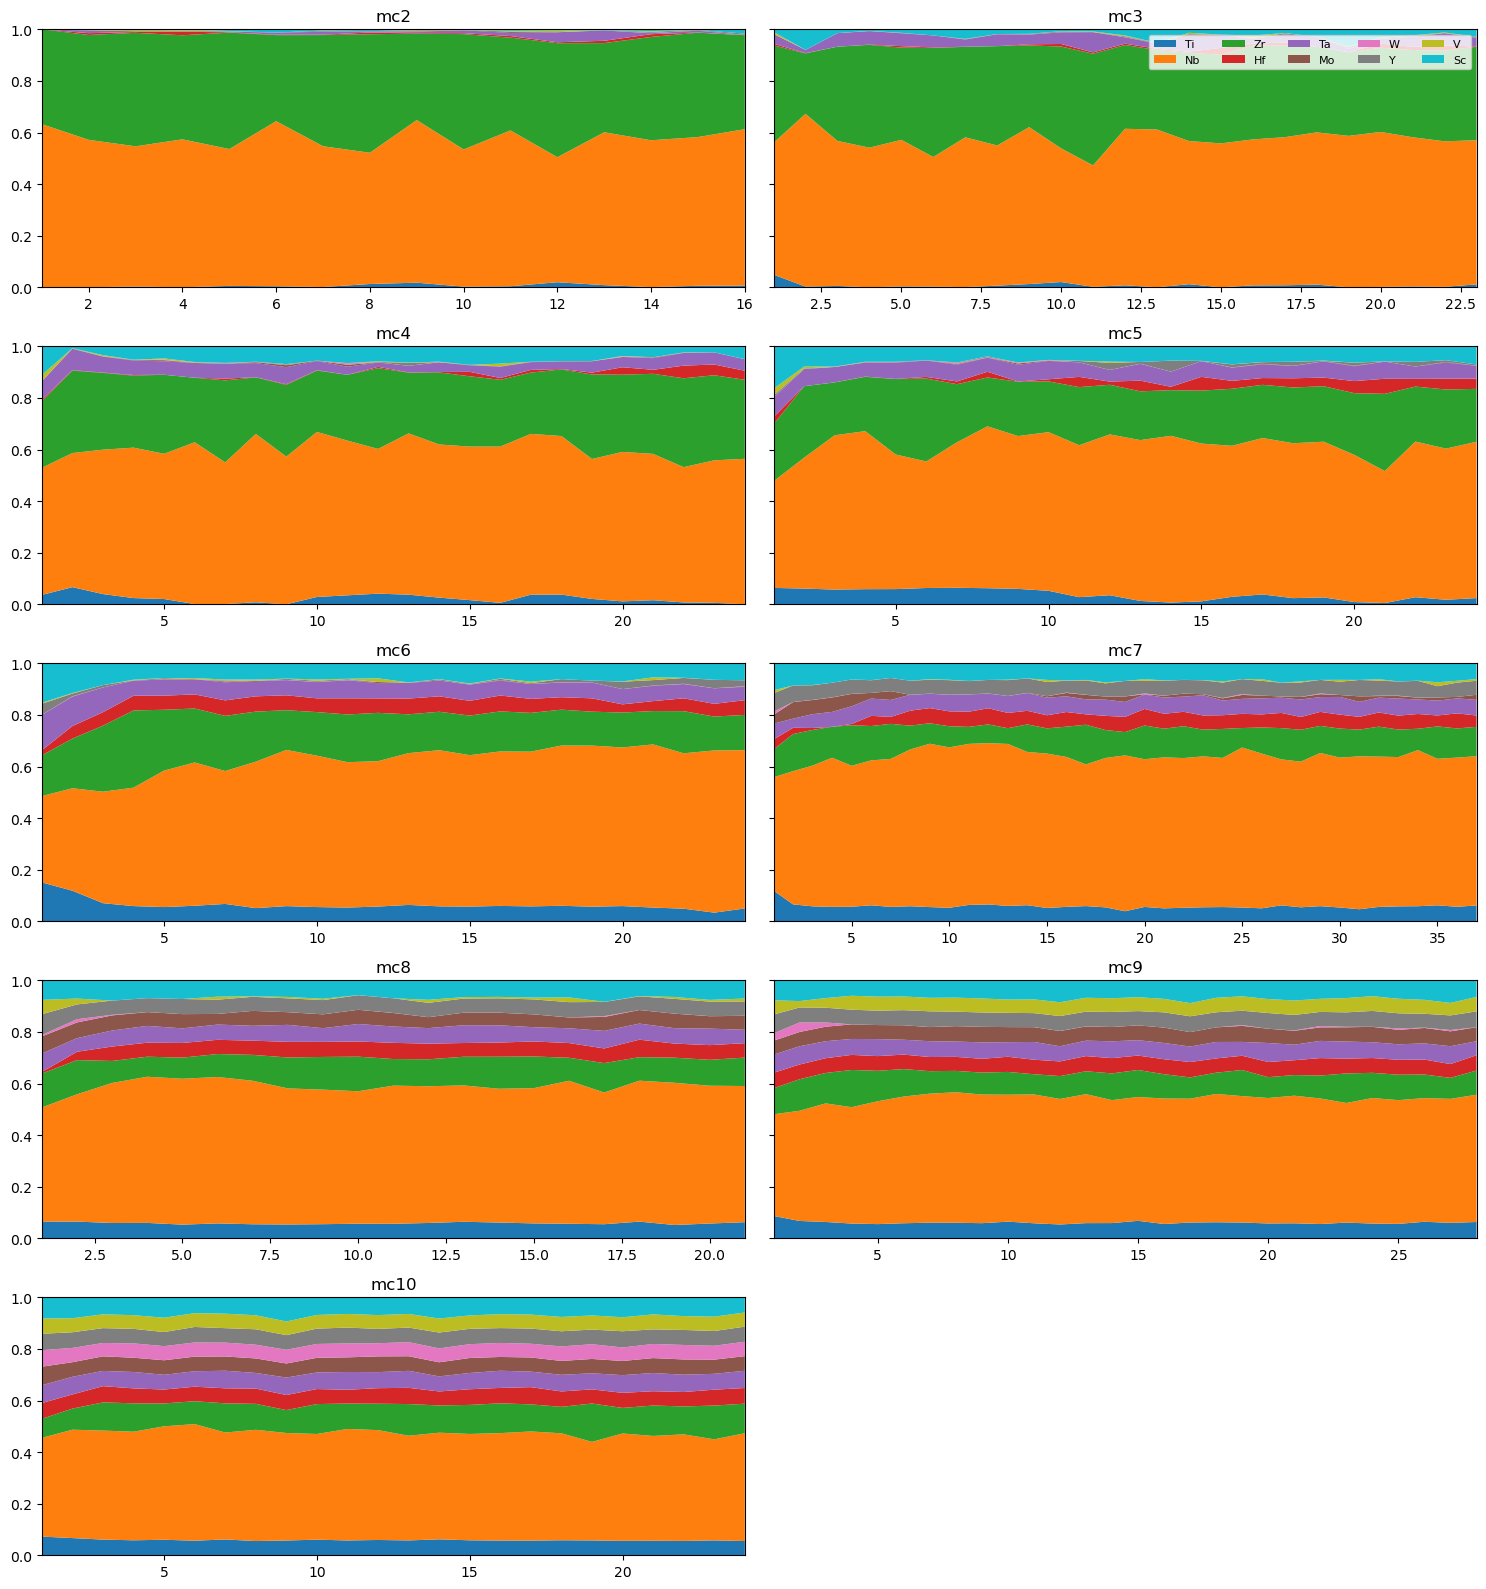

In [6]:
def stack_runs(rs):
    n = len(rs)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(15, 3.2 * ((n + 1) // 2)), sharey=True, squeeze=False)
    for a, r in zip(axes.flat, rs):
        io = r['df'][r['df'].iteration > 0]
        m = io.groupby('iteration')[ELEMENTS].mean()
        a.stackplot(m.index, m.T.values, labels=ELEMENTS, colors=[EL_COLORS[e] for e in ELEMENTS])
        a.set(xlim=(m.index.min(), m.index.max()), ylim=(0, 1), title=r['label'])
    axes.flat[min(1, n - 1)].legend(ncol=5, fontsize=8, loc='upper right')
    for a in list(axes.flat)[n:]:
        a.axis('off')
    plt.tight_layout(); plt.show()

stack_runs(runs)

## 4. Mistrzowie: top 5 poprawnych składów każdego runu

mincomp,iteration,source,Tc,Tc_mu0.1,lam_corr,lam_es,theta_corr,VEC,n_comp,comp
2,1,face,18.97,18.97,1.14,0.000,273,4.61,2,Nb61 Zr39
2,1,face,18.97,18.97,1.14,0.000,273,4.62,2,Nb62 Zr38
2,1,face,18.94,18.94,1.14,0.000,273,4.63,2,Nb63 Zr37
2,1,face,18.90,18.90,1.14,0.000,273,4.64,2,Nb64 Zr36
2,1,face,18.89,18.89,1.14,0.000,273,4.64,2,Nb64 Zr36
3,8,local,17.88,17.88,1.10,0.000,271,4.60,3,Nb54 Zr40 Ta5
3,8,local,17.88,17.88,1.10,0.000,271,4.60,3,Nb54 Zr40 Ta5
3,8,local,17.87,17.87,1.10,0.000,271,4.60,3,Nb54 Zr40 Ta5
3,4,local,17.85,17.85,1.10,0.000,271,4.64,3,Nb59 Zr36 Ta5
3,13,face,17.85,17.03,1.10,0.000,270,4.58,3,Nb63 Zr32 Sc5


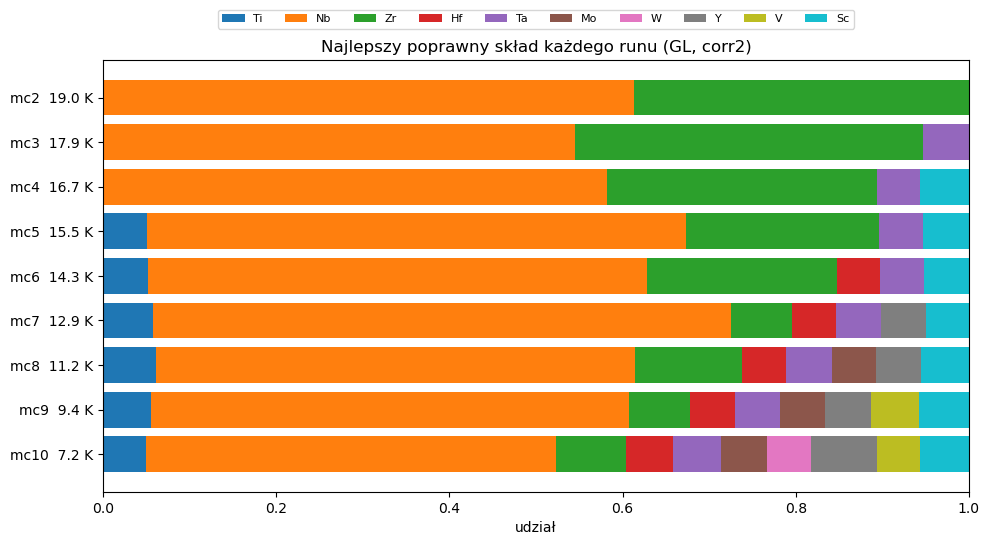

In [7]:
def champ_bar(champ, labels, title):
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(champ) + 1.5))
    left = np.zeros(len(champ))
    for el in ELEMENTS:
        ax.barh(labels, champ[el], left=left, color=EL_COLORS[el], label=el)
        left += champ[el].values
    ax.set(xlabel='udział', title=title); ax.invert_yaxis()
    ax.legend(ncol=10, fontsize=8, loc='lower center', bbox_to_anchor=(.5, 1.06))
    plt.tight_layout(); plt.show()

top = (ALL[ALL.valid].sort_values('Tc', ascending=False)
       .groupby('mincomp').head(5).sort_values(['mincomp', 'Tc'], ascending=[True, False]))
display(top[['mincomp', 'iteration', 'source', 'Tc', 'Tc_mu0.1', 'lam_corr', 'lam_es', 'theta_corr', 'VEC', 'n_comp', 'comp']]
        .style.format({'Tc': '{:.2f}', 'Tc_mu0.1': '{:.2f}', 'lam_corr': '{:.2f}', 'lam_es': '{:.3f}',
                       'theta_corr': '{:.0f}', 'VEC': '{:.2f}'}, na_rep='—').hide(axis='index'))
champ = ALL[ALL.valid].loc[lambda x: x.groupby('mincomp').Tc.idxmax()].set_index('mincomp')
champ_bar(champ, [f'mc{i}  {t:.1f} K' for i, t in zip(champ.index, champ.Tc)], 'Najlepszy poprawny skład każdego runu (GL, corr2)')

## 5. Front Pareto: najlepsze Tc vs liczba pierwiastków

Wszystkie ocenione składy serii mincomp razem (ten sam pipeline i cel); liczone są pierwiastki o udziale > 0.05.

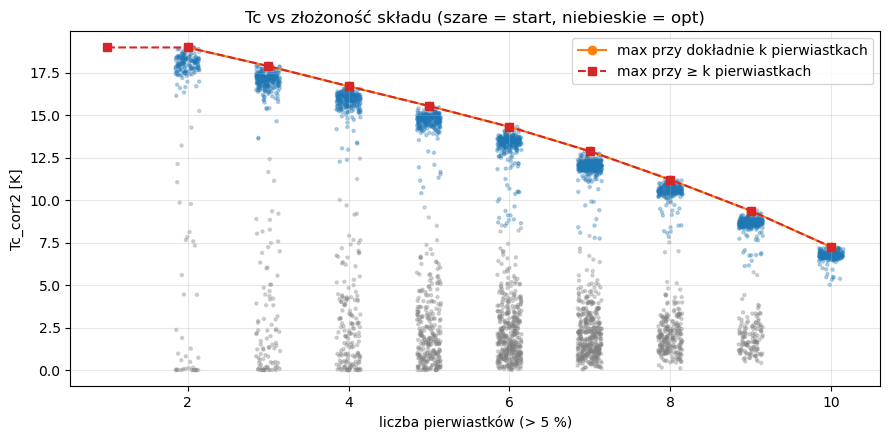

,1,2,3,4,5,6,7,8,9,10
najlepsze Tc przy ≥ k pierwiastkach,18.97,18.97,17.88,16.69,15.53,14.31,12.87,11.2,9.37,7.24


In [8]:
U = ALL.drop_duplicates(subset=ELEMENTS)
front = U.groupby('n_comp').Tc.max()
front_ge = pd.Series({k: U[U.n_comp >= k].Tc.max() for k in range(1, 11)})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(U.n_comp + np.random.default_rng(0).uniform(-.15, .15, len(U)), U.Tc, s=5, alpha=.3,
           c=np.where(U.iteration > 0, 'C0', 'gray'))
ax.plot(front.index, front.values, 'o-', c='C1', label='max przy dokładnie k pierwiastkach')
ax.plot(front_ge.index, front_ge.values, 's--', c='C3', label='max przy ≥ k pierwiastkach')
ax.set(xlabel='liczba pierwiastków (> 5 %)', ylabel=f'{TARGET} [K]', title='Tc vs złożoność składu (szare = start, niebieskie = opt)')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
front_ge.rename('najlepsze Tc przy ≥ k pierwiastkach').to_frame().T.round(2)

## 6. Fizyka mistrzów: λ vs θ_D, λ vs VEC

`Tc_corr2` zależy od θ_corr (θ_mix z θ_bcc dla Sc) i λ_corr = λ·(θ_mix/θ_corr)², pomniejszonego o λ_es dla V, więc na osiach
są te wielkości. Bez V i Sc θ_corr = θ_mix i λ_corr = λ.

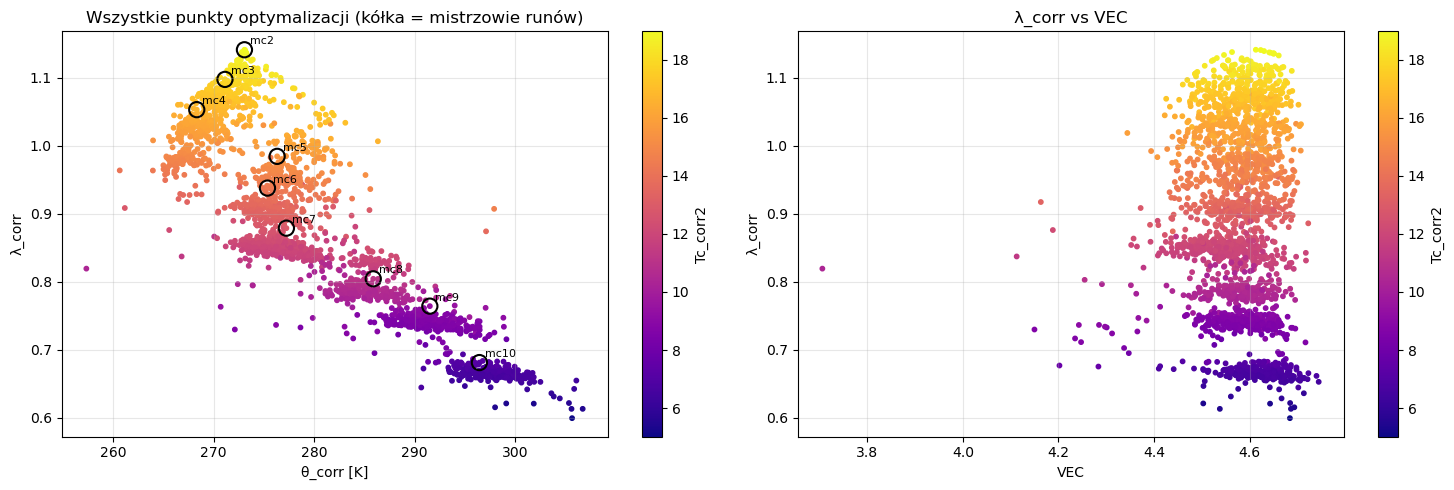

corr(λ_corr, Tc) = 0.995,  corr(θ_corr, Tc) = -0.872


In [9]:
O = ALL[ALL.iteration > 0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sc = ax[0].scatter(O.theta_corr, O.lam_corr, c=O.Tc, s=10, cmap='plasma')
ax[0].scatter(champ.theta_corr, champ.lam_corr, s=120, facecolor='none', edgecolor='k', lw=1.5)
for mc, row in champ.iterrows():
    ax[0].annotate(f'mc{mc}', (row.theta_corr, row.lam_corr), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.colorbar(sc, ax=ax[0], label=TARGET)
ax[0].set(xlabel='θ_corr [K]', ylabel='λ_corr', title='Wszystkie punkty optymalizacji (kółka = mistrzowie runów)')
sc = ax[1].scatter(O.VEC, O.lam_corr, c=O.Tc, s=10, cmap='plasma')
plt.colorbar(sc, ax=ax[1], label=TARGET)
ax[1].set(xlabel='VEC', ylabel='λ_corr', title='λ_corr vs VEC')
for a in ax:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"corr(λ_corr, Tc) = {O[['lam_corr', 'Tc']].corr().iloc[0, 1]:.3f},  "
      f"corr(θ_corr, Tc) = {O[['theta_corr', 'Tc']].corr().iloc[0, 1]:.3f}")

## 7. Jakość surogatu: predykcja CatBoost (przy wyborze) vs wynik KKR

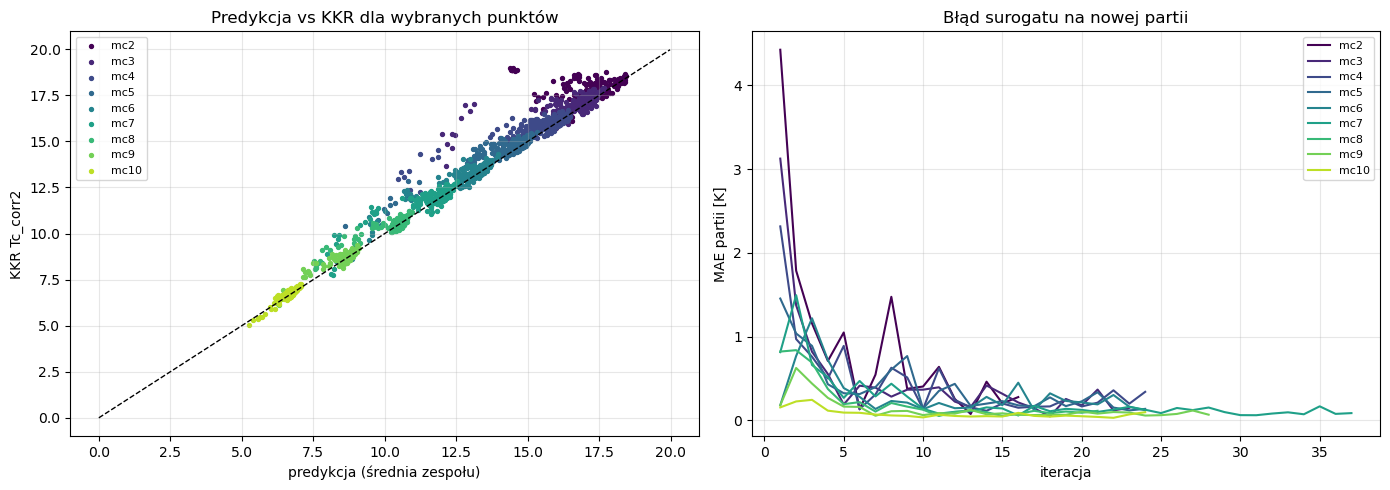

,n,MAE,bias,mean_std,within_1sigma,within_2sigma
label,,,,,,
mc2,160,0.874724,0.830794,1.078461,74%,99%
mc3,230,0.473827,0.385995,0.605487,76%,99%
mc4,240,0.438570,0.381236,0.524598,74%,97%
mc5,240,0.397682,0.369232,0.465865,66%,98%
mc6,240,0.307398,0.251728,0.358616,64%,93%
mc7,370,0.228139,0.125536,0.207982,60%,89%
mc8,210,0.227502,0.150355,0.196802,53%,85%
mc9,280,0.131611,0.049527,0.132363,59%,89%
mc10,240,0.081988,0.030233,0.110844,70%,97%


In [10]:
def surrogate(rs, key='label'):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    out = []
    cm = plt.cm.viridis(np.linspace(0, 0.9, len(rs)))
    for r, c in zip(rs, cm):
        io = r['df'][(r['df'].iteration > 0) & r['df'].pred.notna()]
        err = io.Tc - io.pred; z = err / io.pred_std
        ax[0].scatter(io.pred, io.Tc, s=8, color=c, label=r[key])
        out.append({key: r[key], 'n': len(io), 'MAE': err.abs().mean(), 'bias': err.mean(),
                    'mean_std': io.pred_std.mean(), 'within_1sigma': (z.abs() < 1).mean(), 'within_2sigma': (z.abs() < 2).mean()})
        ax[1].plot(io.assign(ae=err.abs()).groupby('iteration').ae.mean(), color=c, label=r[key])
    lim = [0, max(r['df'].Tc.max() for r in rs) + 1]
    ax[0].plot(lim, lim, 'k--', lw=1)
    ax[0].set(xlabel='predykcja (średnia zespołu)', ylabel=f'KKR {TARGET}', title='Predykcja vs KKR dla wybranych punktów')
    ax[1].set(xlabel='iteracja', ylabel='MAE partii [K]', title='Błąd surogatu na nowej partii')
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    return (pd.DataFrame(out).set_index(key).style.format('{:.2f}')
            .format({'n': '{:d}', 'within_1sigma': '{:.0%}', 'within_2sigma': '{:.0%}'}))

surrogate(runs)

## 8. Skąd pochodzą wybrane punkty (źródło akwizycji)

In [11]:
src = ALL[ALL.iteration > 0].groupby(['mincomp', 'source']).size().unstack(fill_value=0)
src.assign(champion_source=ALL[ALL.valid & (ALL.iteration > 0)].loc[lambda x: x.groupby('mincomp').Tc.idxmax()]
           .set_index('mincomp').source)

source,face,global,local,champion_source
mincomp,,,,
2,15,0,145,face
3,17,0,213,local
4,6,0,234,local
5,2,0,238,local
6,0,0,240,local
7,0,0,370,local
8,0,0,210,local
9,0,6,274,local
10,0,10,230,local


## 9. Odległość mistrza od najlepszego punktu startowego

Odległość euklidesowa w przestrzeni składów między mistrzem runu a jego najlepszym poprawnym punktem startowym.

In [12]:
def travel(rs):
    out = []
    for r in rs:
        v = r['df'][r['df'].valid]
        if not (v.iteration == 0).any():
            out.append(dict(run=r['label'], init_best='— (brak poprawnych punktów startowych)'))
            continue
        b0 = v[v.iteration == 0].loc[lambda x: x.Tc.idxmax()]
        b = v.loc[v.Tc.idxmax()]
        out.append(dict(run=r['label'], init_best=b0.comp, init_Tc=b0.Tc, champion=b.comp, champ_Tc=b.Tc,
                        distance=float(np.linalg.norm(b[ELEMENTS].values.astype(float) - b0[ELEMENTS].values.astype(float)))))
    return pd.DataFrame(out).set_index('run').round(3)

travel(runs)

,init_best,init_Tc,champion,champ_Tc,distance
run,,,,,
mc2,Nb68 Zr32,18.703,Nb61 Zr39,18.974,0.095
mc3,Sc62 Nb25 Zr14,13.612,Nb54 Zr40 Ta5,17.881,0.736
mc4,Nb69 V13 Sc13 Zr5,12.442,Nb58 Zr31 Sc6 Ta5,16.695,0.321
mc5,Nb41 Zr23 Sc10 Ta6 V5 W4 Ti4 Hf4 Mo3,9.568,Nb62 Zr22 Sc5 Ti5 Ta5,15.533,0.229
mc6,Nb28 Sc24 Zr21 Ta10 Mo10 W7,8.511,Nb58 Zr22 Ti5 Sc5 Ta5 Hf5,14.309,0.380
mc7,Nb34 Sc18 Zr16 W9 Y9 Hf8 Ta7,7.893,Nb67 Zr7 Ti6 Ta5 Y5 Hf5 Sc5,12.872,0.377
mc8,Nb52 W9 Zr7 Y7 Ti7 Mo7 Hf6 Sc5,7.510,Nb55 Zr12 Ti6 Sc6 Ta5 Y5 Hf5 Mo5,11.199,0.121
mc9,Nb30 Ti13 Zr13 Mo10 Sc10 Y8 V6 Ta6 Hf5,5.751,Nb55 Zr7 Sc6 V6 Ti6 Mo5 Y5 Hf5 Ta5,9.373,0.279
mc10,— (brak poprawnych punktów startowych),NaN,NaN,NaN,NaN


## 10. Specyfika corr2: gdzie działa poprawka i ile jest V i Sc

Lewy panel: `Tc_corr2` vs `Tc_mu0.1` (szare = start, kolor = mincomp, gwiazdki = mistrzowie). Pod przekątną leżą składy z V
(λ_es obniża Tc), nad przekątną składy ze Sc (niższe θ_D, więc wyższe λ); składy bez V i Sc leżą dokładnie na przekątnej.

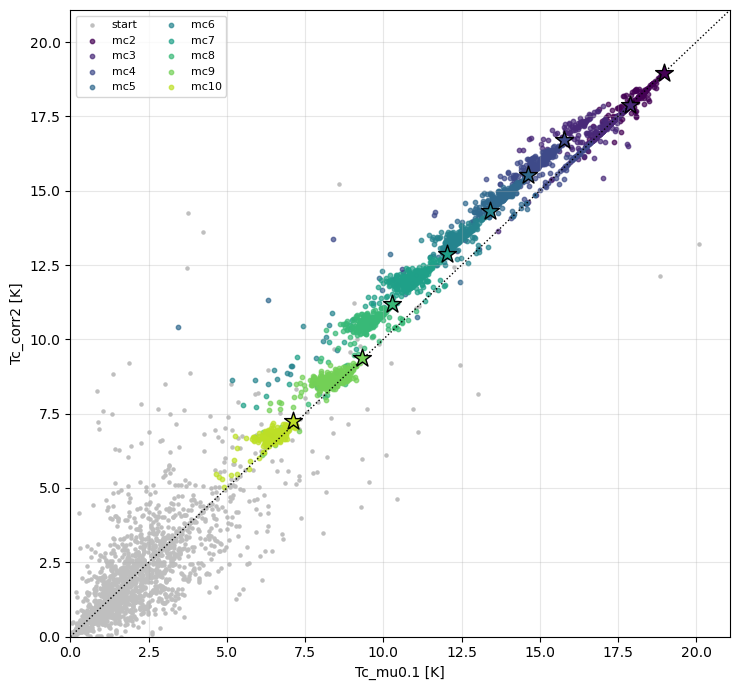

,n,z V > 5 % [%],ze Sc > 5 % [%],śr. V [%],śr. Sc [%],mistrz V [%],mistrz Sc [%],mistrz Tc_corr2 − Tc_mu0.1 [K]
mincomp,,,,,,,,
2,160,0.00,0.62,0.19,0.48,0.00,0.00,0.00
3,230,1.30,32.61,0.18,2.50,0.00,0.00,0.00
4,240,1.67,80.83,0.24,5.39,0.00,5.60,0.93
5,240,1.67,95.00,0.19,6.46,0.00,5.32,0.90
6,240,2.50,99.58,0.28,6.98,0.00,5.23,0.89
7,370,2.43,100.00,0.27,6.77,0.00,5.01,0.85
8,210,13.81,100.00,0.85,6.89,0.00,5.54,0.92
9,280,95.71,100.00,5.22,7.12,5.56,5.73,0.05
10,240,100.00,100.00,5.45,7.13,5.00,5.61,0.12


In [13]:
fig, ax = plt.subplots(figsize=(7.5, 7))
lim = [0, max(ALL[['Tc_mu0.1', 'Tc_corr2']].max()) + 1]
ax.scatter(INIT['Tc_mu0.1'], INIT['Tc_corr2'], s=5, c='0.75', label='start')
for r, c in zip(runs, cmap):
    io = r['df'][r['df'].iteration > 0]
    ax.scatter(io['Tc_mu0.1'], io['Tc_corr2'], s=10, color=c, alpha=.7, label=r['label'])
    b = champ.loc[r['mc']]
    ax.scatter(b['Tc_mu0.1'], b['Tc_corr2'], s=180, marker='*', color=c, edgecolor='k', zorder=5)
ax.plot(lim, lim, 'k:', lw=1)
ax.set(xlim=lim, ylim=lim, xlabel='Tc_mu0.1 [K]', ylabel='Tc_corr2 [K]'); ax.grid(alpha=.3); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

rows = []
for r in runs:
    io = r['df'][r['df'].iteration > 0]
    rows.append({'mincomp': r['mc'], 'n': len(io), 'z V > 5 % [%]': 100 * (io.V > RATIO).mean(),
                 'ze Sc > 5 % [%]': 100 * (io.Sc > RATIO).mean(), 'śr. V [%]': 100 * io.V.mean(),
                 'śr. Sc [%]': 100 * io.Sc.mean(), 'mistrz V [%]': 100 * champ.loc[r['mc']].V,
                 'mistrz Sc [%]': 100 * champ.loc[r['mc']].Sc,
                 'mistrz Tc_corr2 − Tc_mu0.1 [K]': champ.loc[r['mc']].Tc_corr2 - champ.loc[r['mc']]['Tc_mu0.1']})
pd.DataFrame(rows).set_index('mincomp').round(2)

## 11. Wnioski (2026-11-06)

**Przebieg.** Wszystkie 9 runów zakończyło się early stopem (16–37 iteracji). Każdy nowy punkt spełnia mincomp.
Wyszukiwanie jest lokalne: punkty z płaszczyzn sympleksu pojawiają się tylko na początku mc2–5, punkty globalne tylko
w mc9–10. Zysk względem najlepszego poprawnego punktu startowego wynosi +0.3 K dla mc2 (Nb68Zr32 był już w bazie)
i +3.6–6.0 K dla mc3–9. Dla mc10 w bazie nie było żadnego poprawnego punktu startowego.

**Ten sam basen co w składzie A: Nb + Zr, VEC ≈ 4.6.** Mistrzowie mają 47–67 % Nb i 7–40 % Zr, a pozostałe pierwiastki
siedzą na progu ok. 5 %. Dla mc2 i mc3 mistrzowie są praktycznie tacy sami jak w składzie A (Nb61Zr39, Nb54Zr40Ta5).

**Front Pareto** (najlepsze Tc_corr2 przy ≥ k pierwiastkach, k = 2…10): 18.97, 17.88, 16.69, 15.53, 14.31, 12.87,
11.20, 9.37, 7.24 K. Spadek wynosi ok. 1.2–1.9 K na każdy dodatkowy pierwiastek. W składzie A (`OptGL_mu0.1_Runs.ipynb`,
Tc_mu0.1) było to 18.99, 17.92, 16.60, 14.99, 13.52, 11.92, 9.73, 7.22, 4.36 K. Dla k ≥ 4 skład B jest więc wyżej o
0.1–1.5 K, a dla k = 10 o 2.9 K. Dla k = 4–8 różnica pochodzi z dodatku Sc, który z poprawką corr2 podnosi Tc o ok. 0.9 K. Dla k = 9–10 dochodzi to, że w A trzeba było dodać Re i Ru, a w B ich miejsce zajmują V i Sc.

**Fizyka.** Tak jak w A, Tc zależy prawie wyłącznie od λ: corr(λ_corr, Tc) = 0.995. λ_corr mistrza spada z 1.14 (mc2)
do 0.68 (mc10), a θ_corr rośnie z 273 do 296 K, czyli działa przeciwnie i nie kompensuje spadku λ.

**V i Sc.**
- **Sc jest pierwszym dodatkiem** od mc4 i występuje w każdym mistrzu mc4–10 (5–6 %). Daje ok. +0.9 K względem
  Tc_mu0.1: θ_bcc Sc obniża θ_corr o ok. 8 K, a λ_corr rośnie o ok. 5 %.
- **V wchodzi dopiero wtedy, gdy jest wymuszony** (mc9 i mc10, 5–6 %). Przy λ_es ≈ 0.01 kosztuje to tylko 0.05–0.1 K.
- Uwaga: przewaga składu B nad A przy dużym k wynika głównie z poprawki dla Sc. Na 6 jednofazowych stopach ze Sc ta poprawka
  pogarsza zgodność z eksperymentem (`Tc_Baseline_B_corr2.ipynb`), więc tę przewagę trzeba traktować ostrożnie.

**Surogat.** Bias jest dodatni wszędzie (KKR > predykcja), największy dla mc2 (+0.8 K) i maleje do +0.03 K dla mc10.
MAE spada z 0.88 do 0.08 K. Kalibracja σ: 53–76 % punktów mieści się w 1σ.